# 第 1 课：用 Python 生成一条频率曲线

**今天的问题：怎样把“频率随时间变化”写成数据，再让 Python 把它画出来？**

不重复练习第 0 课的运行按钮。我们直接从一条曲线出发，遇到新语法时再解释。

| 小段 | 解决什么问题 | 学完后的检查点 |
|---|---|---|
| A · 列表与索引 | 怎样保存多个数，并取出某一个？ | 修改一个点，解释图上哪里改变 |
| B · 循环 | 怎样让程序重复计算很多个点？ | 改变频率变化速率，预测终点和斜率 |
| C · 函数 | 怎样把一段操作变成可以重复调用的工具？ | 用同一个函数生成上升与下降曲线 |

**本轮先做 A 段，到“检查点 A”暂停，把结果发给讲解者。** B、C 已备好，等 A 段确认理解后继续；不用一次做完。

示例是人为指定的教学频率轨迹，不是实测鲸豚数据，也还没有训练神经网络。

## 0．确认运行入口

仍使用第 0 课的 `HEUhuqiao` 环境。运行下一格，路径应为 `D:\Anaconda3\envs\HEUhuqiao\python.exe`。

这只是环境检查，不要求重新配置。若路径正确，直接进入 A 段。

In [1]:
import sys
print(sys.executable)

D:\Anaconda3\envs\HEUhuqiao\python.exe


## A1．一条曲线，需要一组数

单个 `frequency_khz = 8` 只能表示一个频率。现在我们想记录 5 个时刻的频率，就用 **list（列表）** 将数按顺序放在一起。

- `[ ... ]` 方括号表示列表，元素之间用英文逗号分隔。
- `time_s` 的值以秒为单位，`frequency_khz` 的值以 kHz 为单位。
- 名字末尾的 `_s`、`_khz` 只是帮助我们记住单位；Python 不会自动检查单位。
- 两个列表中的**同一位置配成一对**，例如第一个时间对应第一个频率。

先看代码，预测两个 `print` 会显示一个数，还是一组数。

In [5]:
time_s = [0.0, 0.1, 0.2, 0.3, 0.4]
frequency_khz = [8, 9, 12, 9, 8]

print(time_s)
print(frequency_khz)

[0.0, 0.1, 0.2, 0.3, 0.4]
[8, 9, 12, 9, 8]


这些数据对应的含义是：

| 列表中的位置（索引） | 时间 / s | 频率 / kHz |
|---|---:|---:|
| 0 | 0.0 | 8 |
| 1 | 0.1 | 9 |
| 2 | 0.2 | 10 |
| 3 | 0.3 | 9 |
| 4 | 0.4 | 8 |

这里的 `0.1` 是小数，Python 中常用 `float`（浮点数）表示；`8` 是整数，常用 `int` 表示。这一课不需要转换类型，先认识名称。

**列表记住顺序，程序才知道哪一个频率属于哪一个时刻。**

## A2．索引：从列表里取出一个数

`frequency_khz[2]` 中的方括号表示“按位置取值”，与创建列表的方括号作用不同。

- 索引从 **0** 开始，因此索引 `2` 是第三个元素。
- `[-1]` 表示最后一个元素；`-1` 在这里是索引，不是把频率变成负数。
- `len(...)` 是内置函数，返回列表有多少个元素。
- `print("提示文字", 值)` 可以同时显示说明与结果，中间默认以空格分隔。

运行前，分别预测下面三行的输出。

In [6]:
print("索引 2 的频率：", frequency_khz[2])
print("最后一个频率：", frequency_khz[-1])
print("频率点的个数：", len(frequency_khz))

索引 2 的频率： 12
最后一个频率： 8
频率点的个数： 5


## A3．把对应的时间和频率画出来

使用 Matplotlib 绘图库。先认识下面几句：

- `import matplotlib.pyplot as plt`：引入绘图工具，并给它取短名字 `plt`。之后用 `plt.` 调用它提供的函数。
- `plt.figure(figsize=(6, 3))`：准备一张图；`(6, 3)` 是一对尺寸，单位是英寸。这里只需知道它控制显示大小。
- `plt.plot(time_s, frequency_khz, marker="o")`：横坐标来自第一个列表，纵坐标来自第二个列表；`marker="o"` 用圆点标出数据位置。
- 函数调用括号里的 `marker="o"` 是**按参数名传入设置**，不是在外面创建名叫 marker 的变量。
- `xlabel`、`ylabel` 设置坐标轴名称；`show` 显示图像。

图的英文只用于避免某些环境中的中文字体缺失：Time 是时间，Frequency 是频率。

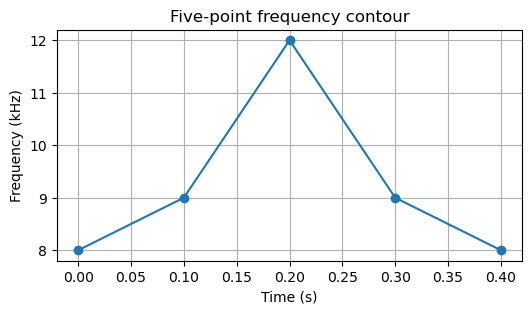

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 3))
plt.plot(time_s, frequency_khz, marker="o")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (kHz)")
plt.title("Five-point frequency contour")
plt.grid(True)
plt.show()

`plt.grid(True)` 打开网格。`True` 是布尔值，表示“真 / 开启”，注意首字母大写；相对应的 `False` 表示“假 / 关闭”。

**图像的含义：**横轴向右是时间增加，纵轴向上是频率增大。圆点之间的线段只是把这 5 个点连接起来，并没有凭空增加新的测量。

这是一张“时间—频率轨迹图”，不是“时间—振幅波形”，也不是短时傅里叶变换得到的完整频谱图。这一课还没有合成可播放的声音。

## 检查点 A · 只改一个点

1. 回到 A1，只把频率列表中**索引 2** 对应的数改成 `12`，保持另外 4 个数不变。
2. 先预测：图像中哪个时间位置会变化？横轴的时间会不会改变？
3. 重新运行 A1，再运行 A2、A3。只运行画图格不会执行你在 A1 中修改过的代码。
4. 用自己的话回答：`frequency_khz[1]` 与 `len(frequency_khz)` 有什么区别？

**提示：**索引 0 是第一个位置，索引 1 是第二个位置；`len` 问的是“有几个”，不是“某个位置的值是多少”。

把“改后的列表、变化发生的时间、上面两个表达式的区别”发给讲解者，或写进 `docs/学习记录.md` 的第 1 课部分。**先停在这里讨论，不必现在就往下赶。**

---

## B1．用循环把点算出来

从这里开始，用**新的变量名**开展第二个例子，不覆盖 A 段的 5 个点。

现在希望从 0 秒到 0.4 秒，每隔 0.01 秒取一个点。如果手写 41 个时间很重复，就让 `for` 循环代劳：

- `dense_time_s = []`：先创建一个空列表。
- `range(41)`：依次给出整数 0、1、…、40，**不包含 41**。
- `for i in range(41):`：依次取出这些整数，每次让名字 `i` 对应其中一个。
- `i * 0.01`：将编号转换为时间；`*` 是乘法。
- `.append(...)`：把一个值追加到列表末尾。
- 冒号 `:` 后，缩进的两行是循环体；约定用 4 个空格。退回左边的 `print` 在整个循环结束后才运行。

不要写成 `dense_time_s = dense_time_s.append(...)`：append 原地修改列表，它的返回值不是修改后的列表。

In [8]:
dense_time_s = []

for i in range(41):
    current_time_s = i * 0.01
    dense_time_s.append(current_time_s)

print("时间点个数：", len(dense_time_s))
print("起点与终点：", dense_time_s[0], dense_time_s[-1])

时间点个数： 41
起点与终点： 0.0 0.4


用前三次循环理解执行过程：

| 本次 i | 算出的时间 | append 之后的列表 |
|---:|---:|---|
| 0 | 0.0 | [0.0] |
| 1 | 0.01 | [0.0, 0.01] |
| 2 | 0.02 | [0.0, 0.01, 0.02] |

41 个点之间有 40 个间隔。最后一次是 `40 * 0.01`，也就是 0.4 秒。

小数在计算机里通常近似表示，有时会看到很长的小数尾巴；目前关注数量、单位和趋势，不把浮点显示误认为程序必然算错。

## B2．为每一个时刻计算频率

先指定一个便于理解的规则：**从 8 kHz 开始，每经过 1 秒增加 10 kHz。**

- `start_khz` 是开始时的频率。
- `rate_khz_per_s` 是每秒变化多少 kHz；正数上升，负数下降。
- 当前频率 = 起始频率 + 每秒变化量 × 已经过的秒数。
- `for t_s in dense_time_s:` 直接依次取出列表中的**时间值**，不是位置编号。

这里的参数由我们写定。后面学习神经网络时，才会研究怎样让程序根据数据调整参数。

In [9]:
start_khz = 8
rate_khz_per_s = 10
dense_frequency_khz = []

for t_s in dense_time_s:
    current_frequency_khz = start_khz + rate_khz_per_s * t_s
    dense_frequency_khz.append(current_frequency_khz)

print("起始频率：", dense_frequency_khz[0])
print("终点频率：", dense_frequency_khz[-1])

起始频率： 8.0
终点频率： 12.0


In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(dense_time_s, dense_frequency_khz)
plt.xlabel("Time (s)")
plt.ylabel("Frequency (kHz)")
plt.title("Frequency generated by a loop")
plt.grid(True)
plt.show()

## 检查点 B · 先预测，再改参数

只把 B2 中 `rate_khz_per_s` 从 `10` 改成 `5`，起始频率仍为 8，时间仍到 0.4 秒。

1. 先写下你预测的终点频率和曲线变化。
2. 重新运行 B2 和它下方的绘图格，比较实际结果。
3. 解释：`range(41)` 为什么最后是 40？`for t_s in dense_time_s` 中的 `t_s` 是时间值，还是索引？

提示：到 0.4 秒时，只经过了 1 秒的 0.4 倍。别把“每秒变化量”和“这段时间总共变化量”混为一谈。

---

## C1．把计算规则放进函数

前面每画一种参数的曲线，都要重复写一段循环。现在把它包装为一个**有输入、有输出的小工具**。

逐行读下方函数：

- `def` 表示“定义函数”，后面是我们起的函数名。
- 括号内的 `times_s, start_khz, rate_khz_per_s` 是 3 个输入的名字，叫参数。
- 函数内部先创建自己的空列表，再用循环逐个算频率。
- `return values_khz` 把整条曲线的数值列表交给调用它的地方。
- `return` 与 `for` 同一层缩进，在循环结束后运行。如果误缩进到循环内部，就会过早结束函数。

**执行定义格，只是让 Python 记住这个工具，不会立即生成曲线。** 后面还要“调用”它。

In [ ]:
def make_linear_contour(times_s, start_khz, rate_khz_per_s):
    values_khz = []
    for t_s in times_s:
        frequency_value = start_khz + rate_khz_per_s * t_s
        values_khz.append(frequency_value)
    return values_khz

## C2．调用函数：同一段代码，换不同输入

下面第一条曲线从 8 kHz 开始，每秒增加 10 kHz；第二条从 12 kHz 开始，每秒减少 10 kHz。

- `dense_time_s` 作为第一个输入，传给函数中的 `times_s`。
- `start_khz=8` 表示按参数名指定输入，便于读清楚含义。
- 函数返回的列表，被赋给 `rising_khz` 或 `falling_khz`。
- 每次调用都会创建新的局部列表，参数使用的是这次传入的值，而不是靠 B2 的同名变量悄悄决定。
- `print` 是显示内容，`return` 是把结果交给调用处，不能互相替代。

如果你修改了函数定义，也要重新运行定义格，再重新运行调用格，已有结果不会自动重算。

In [ ]:
rising_khz = make_linear_contour(dense_time_s, start_khz=8, rate_khz_per_s=10)
falling_khz = make_linear_contour(dense_time_s, start_khz=12, rate_khz_per_s=-10)

print("上升曲线终点：", rising_khz[-1])
print("下降曲线终点：", falling_khz[-1])

下一格在同一张图上调用两次 `plot`，就能比较两条曲线。

`label` 给曲线起图例名称，`plt.legend()` 显示图例。函数根据输入计算数值，绘图代码负责展示；这两个任务可以分开。

In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(dense_time_s, rising_khz, label="rising")
plt.plot(dense_time_s, falling_khz, label="falling")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (kHz)")
plt.title("One function, two sets of parameters")
plt.legend()
plt.grid(True)
plt.show()

## 检查点 C · 独立调用一次

用已有函数生成一条**保持在 9 kHz** 的曲线。

要求：不修改函数内部，不改时间列表，只决定调用时的起始频率和变化速率。在下面的空代码格中自行完成调用与绘图。

提示 1：保持不变意味着“每秒变化量”是多少？

提示 2：把返回的列表赋给新名字，再参考 C2 的绘图方式。

请解释：为什么函数最后用 `return`，不能只写 `print(values_khz)`？这里先不给现成答案，等你尝试后一起检查。

In [ ]:
# 练习 C：在这里调用函数，并画出你生成的曲线。
# 注释行以 # 开头，不会作为计算语句执行。

## 常见问题：按现象找原因

| 现象 | 优先检查 |
|---|---|
| `IndexError: list index out of range` | 5 个元素的非负索引是 0～4，不是 1～5 |
| `IndentationError` | 冒号后是否缩进；循环体与循环外语句是否对齐 |
| `NameError` | 是否从上到下运行过数据、导入和函数定义格；拼写是否一致 |
| plot 提示 x 与 y 长度不同 | 时间和频率列表应有相同个数的元素，逐个对应 |
| 修改代码但图没变 | 是否重新运行了产生数据的格，以及绘图格 |
| 循环得到的点越来越多 | 创建空列表的代码是否也重新执行；本课把它放在循环同一格开头 |
| 函数只返回一个点 | `return` 是否误放到了循环内部 |

不要通过反复点击所有按钮来猜原因；先说清“我改了哪个输入，期待什么输出，实际出现什么”。

## 这与后面的 VAE 有什么关系？

这一课先把“一个样本如何成为一组数字”说清楚。之后会把曲线转换成数组与图像，再把多个样本组织成批次，交给模型。

目前只有我们手写的规则，没有数据学习、损失函数或参数优化。掌握列表、循环和函数，后面才容易看懂模型代码在处理什么。

本课完成的标准：你能修改一个点；预测变化速率对曲线的影响；独立调用函数生成一条曲线，并解释返回结果如何被使用。

这里列出的是验收目标，不表示运行结束就自动掌握。

## 课后保存：继续自己练习 Git

先保存 Notebook 与学习记录。仅当你准备保存当前学习进度时，在仓库根目录的终端执行：

```powershell
git status
git add -- notebooks/01_用Python生成频率曲线.ipynb docs/学习记录.md 计划.md README.md docs/Git操作记录.md
git diff --cached --stat
git commit -m "Practice Python lists loops and functions"
git push origin main
```

本轮只选择第 1 课相关文件。现有手册或你自己的其他脚本若也要保存，另行检查后选择，避免一条 `git add .` 混入不相关内容。

还没做完练习也可以保存“学习中”的版本，只需让提交说明准确表达进度。